# Examine Features
This jupyter notebook assumes you have already processed the images found in ``data/sitters/`` into the ``features.pkl`` file.

In [2]:
import pandas as pd
import numpy as np
import os

features = pd.read_pickle(r'../data2/features_historical.pkl')
features.head()

# keep only existing files
features['full_path'] = '../data2/historical_sitters/' + features['folder'] + '/' + features['filename'] + '.jpg'

# I removed some wrongly processed images in the folder, remove them from the feature dataframe:
features2 = features[features['full_path'].apply(os.path.exists)].copy()

# drop helper column
features2.drop(columns='full_path', inplace=True)

print("Original rows:", len(features))
print("Cleaned rows:", len(features2))
print("Removed rows:", len(features) - len(features2))
features = features2

Original rows: 764
Cleaned rows: 764
Removed rows: 0


In [3]:
len(features2['folder'].unique())

210

In [18]:
# If we only want to evaluate the sitters with more than one face image
filtered_df = features2[features2['folder'].duplicated(keep=False)]

# Sitter 111078 had a photoshoot, with multiple images of the sitter from the same session, this might bias the results.
filtered_df2 = filtered_df[filtered_df['folder'] != '111078']
filtered_df2.head()

,folder,filename,feature
1,p0163,0600-0,"[[-0.5375978, -2.0221865, 1.3104503, -1.434549..."
2,p0163,0599-0,"[[0.7969586, -0.61613005, -1.0911037, -0.05473..."
3,p0114,0403-0,"[[-0.36516213, -0.2687295, -1.2269005, -2.1907..."
4,p0114,0402-0,"[[1.21558, 0.14335568, -1.7924464, -1.0482292,..."
5,p0114,0401-0,"[[-0.3850542, -0.4450745, -1.7605498, -0.46060..."


In [5]:
########### Get the metrics  ###########
"""
This snippet stacks the embeddings (the feature vectors in features.pkl), normalizes the and uses the cosine_similarity metric to calculate the angle between the vectors to evaluate the similarity.
This is then used to calculate the False Positive Rate (FPR), True Positive Rate (TPR) for several thresholds.
"""

from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
from sklearn.preprocessing import normalize

df = features2

embeddings = np.stack(df['feature'].values).squeeze(1)
norm_embeddings = normalize(embeddings, norm='l2')
similarity_matrix = cosine_similarity(embeddings)  # shape (N, N)
print(similarity_matrix.shape)

identities = df['folder'].values
identity_matrix = np.equal.outer(identities, identities).astype(int)  # (N, N)

i, j = np.triu_indices_from(similarity_matrix, k=1)

similarities = similarity_matrix[i, j]        # similarity scores
labels = identity_matrix[i, j]

from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(1-labels,1-similarities)
print(fpr)
print(tpr)
print(thresholds)
roc_auc = auc(fpr, tpr)
print(1-similarities)

(764, 764)
[0.         0.         0.         ... 0.99935484 0.99935484 1.        ]
[0.00000000e+00 3.44927496e-06 8.65768016e-04 ... 9.99993101e-01
 1.00000000e+00 1.00000000e+00]
[           inf  1.2092556e+00  1.1156508e+00 ...  6.4202905e-02
 -1.1920929e-07 -2.3841858e-07]
[0.9080904  0.9560672  0.9299571  ... 0.36286545 0.33041328 0.50919217]


In [6]:
########### Leave One Out ###########
"""
This snippet calculates the leave one out validation technique
We stack the embeddings (the feature vectors in features.pkl) and use the cosine_similarity metric to calculate the angle between the vectors to evaluate the similarity.
This is then used to calculate the False Positive Rate (FPR), True Positive Rate (TPR) for several thresholds.
"""

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import roc_curve


def leave_one_out_from_df(df: pd.DataFrame):
    genuine_scores = []
    imposter_scores = []

    for idx, row in df.iterrows():
        probe_id = row["folder"]
        probe_feat = row["feature"].reshape(1, -1)

        # Genuine comparisons (same identity, exclude self)
        genuine_feats = df[(df["folder"] == probe_id) & (df.index != idx)]["feature"]
        if len(genuine_feats) > 0:
            g_scores = cosine_similarity(probe_feat, np.vstack(genuine_feats))[0]
            genuine_scores.extend(g_scores)

        # Imposter comparisons (different identity)
        imposter_feats = df[df["folder"] != probe_id]["feature"]
        if len(imposter_feats) > 0:
            i_scores = cosine_similarity(probe_feat, np.vstack(imposter_feats))[0]
            imposter_scores.extend(i_scores)

    return np.array(genuine_scores), np.array(imposter_scores)


# Calculate
genuine, imposter = leave_one_out_from_df(df)

# Compute EER
y_true = np.concatenate([np.ones_like(genuine), np.zeros_like(imposter)])
y_scores = np.concatenate([genuine, imposter])
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
eer_idx = np.nanargmin(np.abs(fpr - (1 - tpr)))
eer = fpr[eer_idx]
print("EER:", eer)


EER: 0.1460388526331765


EER threshold: 0.23991303
Genuine range: -0.040883392 1.0000001
Impostor range: -0.20925556 1.0000001


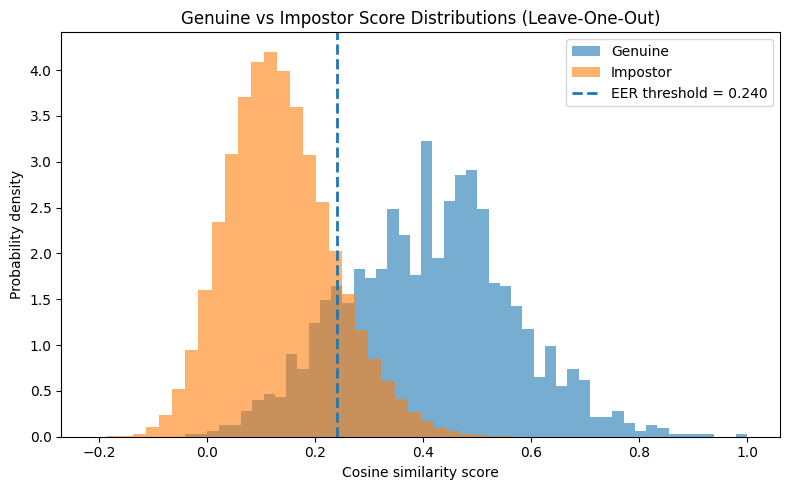

In [7]:
eer_threshold = thresholds[eer_idx]
print("EER threshold:", eer_threshold)

print("Genuine range:", genuine.min(), genuine.max())
print("Impostor range:", imposter.min(), imposter.max())

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# Genuine scores
plt.hist(
    genuine,
    bins=50,
    density=True,
    alpha=0.6,
    label="Genuine",
)

# Impostor scores
plt.hist(
    imposter,
    bins=50,
    density=True,
    alpha=0.6,
    label="Impostor",
)

# EER threshold
plt.axvline(
    eer_threshold,
    linestyle="--",
    linewidth=2,
    label=f"EER threshold = {eer_threshold:.3f}",
)

plt.xlabel("Cosine similarity score")
plt.ylabel("Probability density")
plt.title("Genuine vs Impostor Score Distributions (Leave-One-Out)")
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.savefig(os.path.join('../figures', f"genuine_vs_impostor_score_distribution.png"))
plt.show()

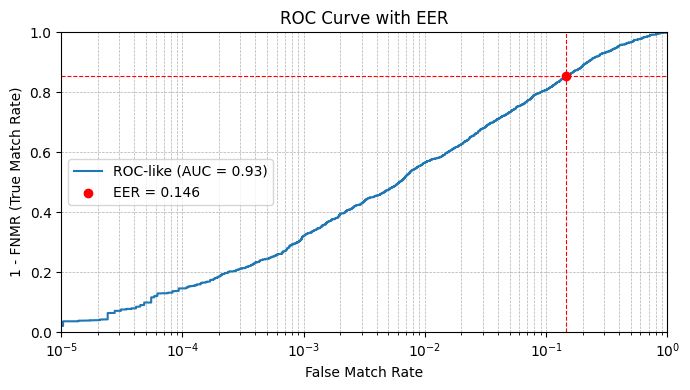

In [8]:
from matplotlib import pyplot as plt

# Compute FNMR (False Non-Match Rate)
fnmr = 1 - tpr
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(7,4))

# Plot FMR (x) vs 1 - FNMR (y), i.e. TPR
plt.plot(fpr, 1 - fnmr, label=f'ROC-like (AUC = {roc_auc:.2f})')

# Plot chance line (random performance)
# plt.plot([1e-6, 1], [0, 1], 'k--', label='Chance')

# Plot EER point
plt.scatter(fpr[eer_idx], 1 - fnmr[eer_idx],
            c='red', zorder=5, label=f'EER = {eer:.3f}')
plt.axvline(fpr[eer_idx], color='red', linestyle='--', linewidth=0.8)
plt.axhline(1 - fnmr[eer_idx], color='red', linestyle='--', linewidth=0.8)

# Axis settings
plt.xscale('log')
plt.xlim([1e-5, 1])   # log scale needs strictly positive values
plt.ylim([0, 1])

plt.xlabel('False Match Rate')
plt.ylabel('1 - FNMR (True Match Rate)')
plt.title('ROC Curve with EER')
plt.legend()
plt.grid(True, which="both", ls="--", linewidth=0.5)
plt.tight_layout()
plt.savefig(os.path.join('../figures', f"log_roc_curve_with_EER.png"))
plt.show()

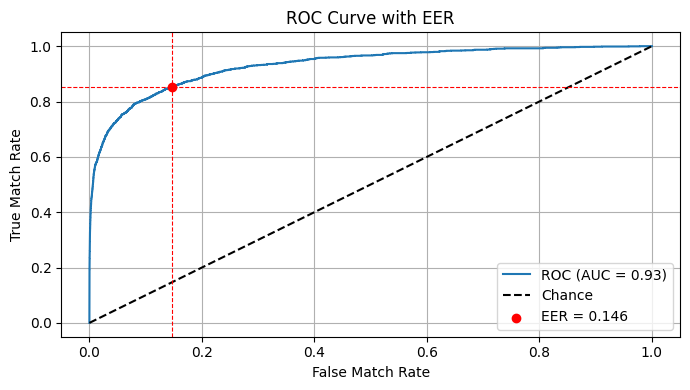

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(fpr, tpr, label=f'ROC (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Chance')

# Plot EER point
plt.scatter(fpr[eer_idx], tpr[eer_idx], c='red', zorder=5, label=f'EER = {eer:.3f}')
plt.axvline(fpr[eer_idx], color='red', linestyle='--', linewidth=0.8)
plt.axhline(tpr[eer_idx], color='red', linestyle='--', linewidth=0.8)

plt.xlabel('False Match Rate')
plt.ylabel('True Match Rate')
plt.title('ROC Curve with EER')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join('../figures', f"roc_curve_with_EER.png"))
plt.show()

In [10]:
# Target FARs (false accept rates)
target_fars = [0.00001, 0.00005, 0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1]   # 0.01%, 0.1%, 1%, 10%

results = []
for target_fpr in target_fars:
    idxs = np.where(fpr <= target_fpr)[0]
    if len(idxs) > 0:
        best_idx = idxs[np.argmax(tpr[idxs])]
        results.append({
            "FAR": target_fpr,
            "#False Matches": target_fpr*194,
            "TAR": tpr[best_idx],
            "FNMR": 1 - tpr[best_idx],
            "Threshold": thresholds[best_idx]
        })
    else:
        results.append({
            "FAR": target_fpr,
            "TAR": None,
            "Threshold": None
        })

df_results = pd.DataFrame(results)
print(df_results)

       FAR  #False Matches       TAR      FNMR  Threshold
0  0.00001         0.00194  0.020645  0.979355   0.739059
1  0.00005         0.00970  0.098710  0.901290   0.610794
2  0.00010         0.01940  0.145806  0.854194   0.569205
3  0.00050         0.09700  0.244516  0.755484   0.513668
4  0.00100         0.19400  0.320000  0.680000   0.486811
5  0.00500         0.97000  0.475484  0.524516   0.424032
6  0.01000         1.94000  0.565161  0.434839   0.393414
7  0.05000         9.70000  0.733548  0.266452   0.311156
8  0.10000        19.40000  0.807742  0.192258   0.267377


In [11]:
print(tpr)
print(fpr)

# Target FAR
target_fpr = 0.1

# Find all thresholds where FPR <= 0.001
indices = np.where(fpr <= target_fpr)[0]

# Choose the one with highest TPR (best trade-off)
best_idx = indices[np.argmax(tpr[indices])]

# Threshold at FAR = 0.1%
threshold_at_far = thresholds[best_idx]
preds = (similarities >= threshold_at_far).astype(int)

from sklearn.metrics import accuracy_score

acc = accuracy_score(labels, preds)
print(f'Accuracy at FAR = {target_fpr*100:.2f}%: {acc*100:.2f}%')

[0.0000000e+00 6.4516129e-04 6.4516129e-04 ... 1.0000000e+00 1.0000000e+00
 1.0000000e+00]
[0.00000000e+00 3.44927496e-06 6.89854992e-06 ... 9.99865478e-01
 9.99868928e-01 1.00000000e+00]
Accuracy at FAR = 10.00%: 90.03%


# T-SNE Evaluation
T-SNE can be used to find clusters in high dimensional data. This is purely a visualization tool.

In [11]:
# import matplotlib.pyplot as plt
# import seaborn as sns
# from sklearn.manifold import TSNE
#
# df = filtered_df2 # Only the multi-face sitters
#
# feature_emb = np.stack(df['feature'].values).squeeze(1)
# # print(feature_emb.shape, type(feature_emb))
# # print(feature_emb)
#
#
# metrics = TSNE(n_components=2).fit_transform(norm_embeddings)
# sorting = np.argsort(df['folder'].values)
# new_labels = np.array([f'id {label}' for label in df['folder'].values.astype(int)])[sorting]
# tsnex = np.array(metrics[:, 0])[sorting]
# tsney = np.array(metrics[:, 1])[sorting]
#
# df = pd.DataFrame([new_labels, tsnex, tsney], index=['label', 'tsne_x', 'tsne_y'])
#
# df = df.transpose()
# plt.figure()
# g = sns.scatterplot(x='tsne_x', y='tsne_y', hue='label', palette="rainbow", data=df)
# g.legend(loc='center left', bbox_to_anchor=(1, 0.5), title="painting id's")
# plt.title(f't-SNE')

ValueError: invalid literal for int() with base 10: 'p0163'

# Similarity Matrix
Shows the faces that are classified the same for a certain threshold. The identities on the diagonal are the same.

In [12]:
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns

df = filtered_df2
df.head()
#
# identities = df['folder'].values
# print(len(identities))
# embeddings = np.stack(df['feature'].values).squeeze(1)
# similarity_matrix = cosine_similarity(embeddings)
# print(similarity_matrix)
#
# # thresh = 0.5
# # similarity_matrix[similarity_matrix <= thresh] = 0
# # similarity_matrix[similarity_matrix > thresh] = 1
# fig, ax = plt.subplots(figsize=(10,10))
# sns.heatmap(similarity_matrix, linewidths=.5, ax=ax)

,folder,filename,feature
1,p0163,0600-0,"[[-0.5375978, -2.0221865, 1.3104503, -1.434549..."
2,p0163,0599-0,"[[0.7969586, -0.61613005, -1.0911037, -0.05473..."
3,p0114,0403-0,"[[-0.36516213, -0.2687295, -1.2269005, -2.1907..."
4,p0114,0402-0,"[[1.21558, 0.14335568, -1.7924464, -1.0482292,..."
5,p0114,0401-0,"[[-0.3850542, -0.4450745, -1.7605498, -0.46060..."


# Creating folder with similarity pairs above threshold